# 5. Model Fit: Overfitting on Fashion-MNIST

Last week we built our first neural network with `PyTorch` and, in the last coding task, tracked training and test accuracy after every epoch.
This week we take that network to a harder dataset and then **deliberately make it overfit**, so we can see what overfitting looks like in the loss and accuracy curves.

We split the data into **training**, **validation** and **test** data, train on the training data, watch the validation data during training, and use the test data only once at the very end.

## Part 1: Make the network overfit

### Load Fashion-MNIST

[Fashion-MNIST](https://github.com/zalandoresearch/fashion-mnist) has the same format as MNIST: 70,000 grayscale images of 28x28 = 784 pixels, 10 classes.
But instead of digits, the images show clothing items, which makes the task considerably harder.
We load it the same way as MNIST last week (the first download takes a minute):

In [88]:
from sklearn.datasets import fetch_openml
X, y = fetch_openml('Fashion-MNIST', version=1, return_X_y=True, cache=True, parser='auto')
X.shape

(70000, 784)

The data looks exactly like MNIST, one column per pixel:

In [89]:
X.head(3)

,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,pixel9,pixel10,...,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783,pixel784
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,1,0,0,0,0,...,119,114,130,76,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,22,...,0,0,1,0,0,0,0,0,0,0


The label is again a number between 0-9, but now each number stands for a type of clothing:

In [90]:
class_names = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
               "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]
y.head(3)

0    9
1    0
2    0
Name: class, dtype: category
Categories (10, str): ['0', '1', '2', '3', ..., '6', '7', '8', '9']

Let's look at one example image per class:

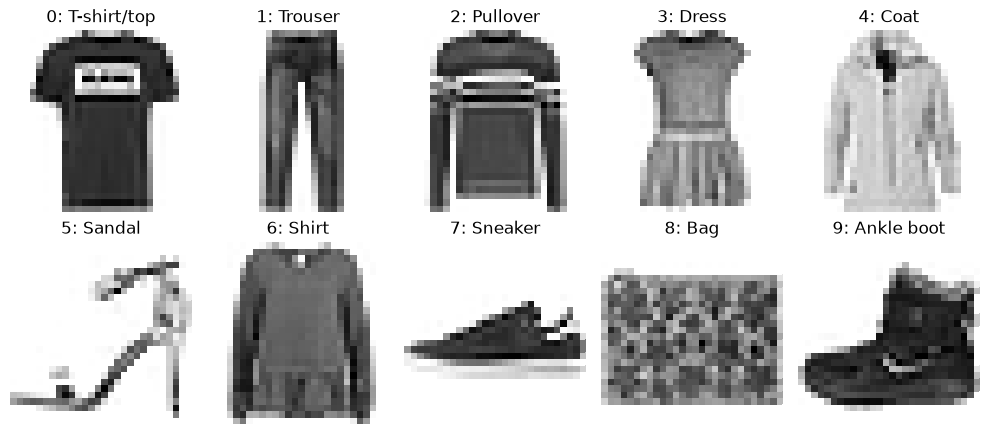

In [91]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 5, figsize=(10, 4.5))
for label, ax in enumerate(axes.flat):
    idx = (y.astype(int) == label).values.argmax()   # first image with this label
    ax.imshow(X.iloc[idx].values.reshape(28, 28), cmap="gray_r")
    ax.set_title(f"{label}: {class_names[label]}")
    ax.axis("off")
plt.tight_layout()

### Prepare the data: train, validation and test

We scale the pixels to [0, 1] as last week. Then we split the data into three parts:
- **Test data:** the last 10,000 images (this is the official Fashion-MNIST test set). We only use it at the very end.
- **Validation data:** 10,000 images that we evaluate after every epoch to monitor overfitting.
- **Training data:** we use only **5,000** images. This keeps training fast on a CPU, and it makes overfitting appear within a few hundred epochs. (Less training data is also one of the reasons for overfitting from the lecture.)

In [92]:
from sklearn.model_selection import train_test_split

X_scaled = (X/255).astype('float32').values
y = y.astype('long').values

X_pool, y_pool = X_scaled[:60000], y[:60000]   # official training part
X_test, y_test = X_scaled[60000:], y[60000:]   # official test part

X_train, X_val, y_train, y_val = train_test_split(
    X_pool, y_pool, train_size=5000, test_size=10000, random_state=42, stratify=y_pool)
X_train.shape, X_val.shape, X_test.shape

((5000, 784), (10000, 784), (10000, 784))

As last week, we select the device and convert everything into PyTorch tensors:

In [93]:
import torch
import torch.nn as nn
torch.manual_seed(0) # to ensure reproducibility

if torch.backends.mps.is_available():
    device = torch.device("mps")
    print(f"Using {device} device")
else:
    print ("MPS device not found.")

Using mps device


In [94]:
train_x = torch.Tensor(X_train).float().to(device)
val_x = torch.Tensor(X_val).float().to(device)
test_x = torch.Tensor(X_test).float().to(device)
train_y = torch.Tensor(y_train).long().to(device)
val_y = torch.Tensor(y_val).long().to(device)
test_y = torch.Tensor(y_test).long().to(device)

### A reusable training function

We will train several networks, so we put last week's training loop (including the accuracy tracking from coding task 3) into a function.
After every epoch it measures loss and accuracy on the training **and** the validation data and stores them in a dictionary `history`.

Note that we evaluate in `eval()` mode and inside `torch.no_grad()`: we do not need gradients for evaluation, and some layers (e.g. dropout) behave differently during training and evaluation.

In [95]:
loss_func = nn.CrossEntropyLoss()

def evaluate(model, x, y):
    """Returns (loss, accuracy) of the model on the data x, y."""
    model.eval()
    with torch.no_grad():
        y_hat = model(x)
        loss = loss_func(y_hat, y).item()
        accuracy = (torch.argmax(y_hat, 1) == y).float().mean().item()
    return loss, accuracy


def train(model, optimizer, no_epochs, print_every=100):
    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
    for epoch in range(no_epochs):

        model.train()   # evaluate() below switches to eval mode, so switch back every epoch (matters for dropout)
        optimizer.zero_grad()
        y_hat = model(train_x)            # all training points (= batch gradient descent)
        loss = loss_func(y_hat, train_y)
        loss.backward()
        optimizer.step()

        train_loss, train_acc = evaluate(model, train_x, train_y)
        val_loss, val_acc = evaluate(model, val_x, val_y)
        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_acc"].append(train_acc)
        history["val_acc"].append(val_acc)

        if epoch % print_every == 0:
            print(f"Epoch {epoch}: train loss {train_loss:.3f}, val loss {val_loss:.3f}, "
                  f"train acc {train_acc:.3f}, val acc {val_acc:.3f}")
    return history

And a function that plots loss and accuracy curves next to each other. The dashed line marks the epoch with the lowest validation loss:

In [96]:
""" You do not have to read this cell in detail """
import numpy as np

def plot_history(history, title=""):
    best_epoch = int(np.argmin(history["val_loss"]))
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
    ax1.plot(history["train_loss"], label="training loss")
    ax1.plot(history["val_loss"], label="validation loss")
    ax1.set_xlabel("number of epochs"); ax1.set_ylabel("loss")
    ax2.plot(history["train_acc"], label="training accuracy")
    ax2.plot(history["val_acc"], label="validation accuracy")
    ax2.set_xlabel("number of epochs"); ax2.set_ylabel("accuracy")
    for ax in (ax1, ax2):
        ax.axvline(best_epoch, color="gray", linestyle="--", label=f"lowest val loss (epoch {best_epoch})")
        ax.legend()
    fig.suptitle(title)
    fig.tight_layout()
    plt.show()

The curves can be a bit noisy from epoch to epoch. To compare models, we therefore average the last 20 epochs:

In [97]:
def summary(history, name=""):
    """Averages over the last 20 epochs: train acc, val acc, gap, val loss."""
    train_acc = np.mean(history["train_acc"][-20:])
    val_acc = np.mean(history["val_acc"][-20:])
    val_loss = np.mean(history["val_loss"][-20:])
    gap = train_acc - val_acc
    if name:
        print(f"{name:22s}: train acc {train_acc:.3f}, val acc {val_acc:.3f}, gap {gap:.3f}, "
              f"val loss {val_loss:.3f} (lowest: {min(history['val_loss']):.3f})")
    return train_acc, val_acc, gap, val_loss

### Step 1: Last week's network on Fashion-MNIST

We start with the network from last week. For training we now use the **Adam** optimizer (see the gradient descent variants from week 3) instead of plain SGD. We use the same optimizer settings for all networks in this notebook, so that differences between the networks come from the architecture, not from the optimizer.

### Task 1: Define last week's network
Write a class `DeepNeuralNetwork` (inheriting from `nn.Module`) with a constructor `__init__` and a `forward` method. The network has the following layers:
- Input layer of size 784
- First hidden layer of size 128 with sigmoid activation
- Second hidden layer of size 64 with sigmoid activation
- Output layer of size 10 (no activation, the softmax is part of `CrossEntropyLoss`)

In [98]:
import torch.nn as nn

class DeepNeuralNetwork(nn.Module): # the class has to inherit from nn.Module
    def __init__(self):
        
        super(DeepNeuralNetwork, self).__init__()  # calling super constructor
        
        # defining layers
        self.hidden1 = nn.Linear(784, 128)
        self.hidden2 = nn.Linear(128, 64)
        self.output = nn.Linear(64, 10)

    def forward(self, x):
        
        z1 = self.hidden1(x)
        a1 = torch.sigmoid(z1)
        z2 = self.hidden2(a1)
        a2 = torch.sigmoid(z2)
        z3 = self.output(a2)
        # note: we do not apply the softmax here!
        return z3

In [99]:
# check for task 1: do not change this cell
test_model = DeepNeuralNetwork()
n_params = sum(p.numel() for p in test_model.parameters())
assert n_params == 109386, f"DeepNeuralNetwork has {n_params} parameters, but should have 109,386 - check the layer sizes"
assert test_model(torch.zeros(2, 784)).shape == (2, 10), "the network should return 10 scores per image"
print("All checks passed!")

All checks passed!


Now we create the network and train it:

In [100]:
torch.manual_seed(0)
dnn = DeepNeuralNetwork().to(device)
print("Number of parameters:", sum(p.numel() for p in dnn.parameters()))

optimizer = torch.optim.Adam(dnn.parameters(), lr=0.0005)
history_small = train(dnn, optimizer, no_epochs=300, print_every=30)

Number of parameters: 109386
Epoch 0: train loss 2.361, val loss 2.361, train acc 0.100, val acc 0.100
Epoch 30: train loss 2.150, val loss 2.151, train acc 0.331, val acc 0.338
Epoch 60: train loss 1.860, val loss 1.859, train acc 0.371, val acc 0.372
Epoch 90: train loss 1.626, val loss 1.624, train acc 0.492, val acc 0.498
Epoch 120: train loss 1.452, val loss 1.450, train acc 0.548, val acc 0.551
Epoch 150: train loss 1.312, val loss 1.310, train acc 0.571, val acc 0.573
Epoch 180: train loss 1.196, val loss 1.194, train acc 0.603, val acc 0.598
Epoch 210: train loss 1.096, val loss 1.096, train acc 0.636, val acc 0.632
Epoch 240: train loss 1.008, val loss 1.009, train acc 0.671, val acc 0.665
Epoch 270: train loss 0.931, val loss 0.934, train acc 0.691, val acc 0.685


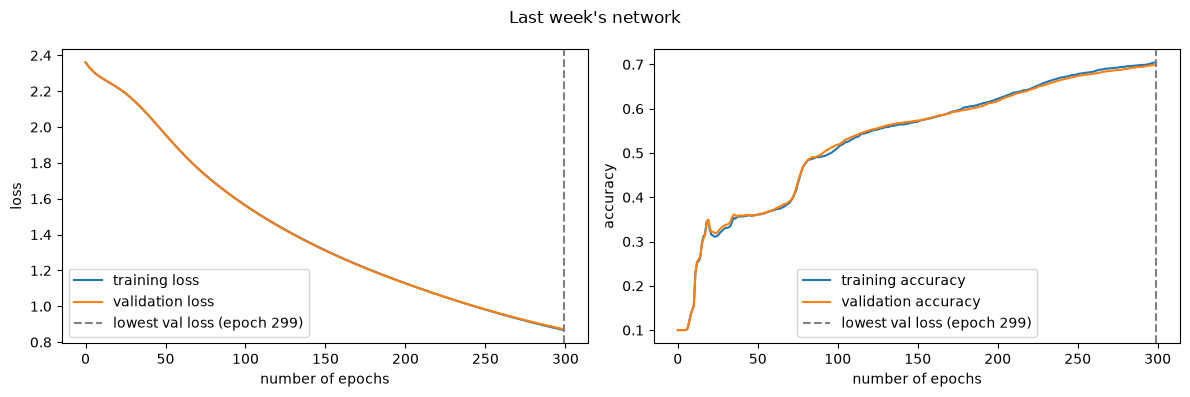

In [101]:
plot_history(history_small, "Last week's network")

**Question:** Is this model overfitting, underfitting, or well fitted? Look at both the gap between the curves and at how the curves are behaving at the end of training.

*Your answer:* Das Modell ist underfitted. Die Trainings- und Validierungskurven liegen fast genau übereinander. Es gibt also keine Lücke (Gap) zwischen ihnen und damit auch kein Overfitting: Das Modell generalisiert genauso gut, wie es die Trainingsdaten lernt. Allerdings ist schon die Leistung auf den Trainingsdaten schwach (≈69 % Accuracy, Loss ≈0,93 nach 300 Epochen). Außerdem fällt der Loss am Ende des Trainings noch deutlich und die Accuracy steigt weiter, die Kurven sind also noch nicht konvergiert. Das Modell hat die Muster in den Daten noch nicht gut genug gelernt, es ist also underfitted. Längeres Training, ReLU statt Sigmoid oder mehr Kapazität sollten das Ergebnis verbessern. Genau das machen wir in Step 2.

### Step 2: Extend the network until it overfits

To provoke overfitting we give the network much more **capacity** (see lecture). We make two changes:
1. **Wider and deeper:** three hidden layers with 512, 512 and 256 neurons.
2. **ReLU** instead of sigmoid in the hidden layers, so that the deeper network trains well.

### Task 2: Define the extended network
Write a class `BigNetwork` in the same way as `DeepNeuralNetwork` in Task 1, i.e. implement the constructor `__init__` and the `forward` method. The network has the following layers:
- Input layer of size 784
- First hidden layer of size 512 with ReLU activation
- Second hidden layer of size 512 with ReLU activation
- Third hidden layer of size 256 with ReLU activation
- Output layer of size 10 (no activation, as last week)

Hint: `torch.relu` works just like `torch.sigmoid`.

In [102]:
import torch.nn as nn

class BigNetwork(nn.Module): # the class has to inherit from nn.Module
    def __init__(self):
        
        super(BigNetwork, self).__init__()  # calling super constructor
        
        # defining layers
        self.hidden1 = nn.Linear(784, 512)
        self.hidden2 = nn.Linear(512, 512)
        self.hidden3 = nn.Linear(512, 256)
        self.output = nn.Linear(256, 10)

    def forward(self, x):
        
        z1 = self.hidden1(x)
        a1 = torch.relu(z1)
        z2 = self.hidden2(a1)
        a2 = torch.relu(z2)
        z3 = self.hidden3(a2)
        a3 = torch.relu(z3)
        z4 = self.output(a3)
        # note: we do not apply the softmax here!

        return z4

In [103]:
# check for task 2: do not change this cell
test_model = BigNetwork()
n_params = sum(p.numel() for p in test_model.parameters())
assert n_params == 798474, f"BigNetwork has {n_params} parameters, but should have 798,474 - check the layer sizes"
assert test_model(torch.zeros(2, 784)).shape == (2, 10), "the network should return 10 scores per image"
print("All checks passed!")

All checks passed!


Now we create the network and compare its size with the amount of training data:

In [104]:
torch.manual_seed(0)
big = BigNetwork().to(device)
print("Number of parameters:", sum(p.numel() for p in big.parameters()))
print("Number of training images:", len(train_x))

Number of parameters: 798474
Number of training images: 5000


The network now has about 800,000 parameters, i.e. more than 150 parameters per training image. We train it with the same settings as before (this takes about one or two minutes on a CPU):

In [105]:
optimizer = torch.optim.Adam(big.parameters(), lr=0.0005)
history_big = train(big, optimizer, no_epochs=300, print_every=30)

Epoch 0: train loss 2.272, val loss 2.272, train acc 0.154, val acc 0.155
Epoch 30: train loss 0.675, val loss 0.664, train acc 0.733, val acc 0.742
Epoch 60: train loss 0.479, val loss 0.504, train acc 0.828, val acc 0.822
Epoch 90: train loss 0.385, val loss 0.452, train acc 0.864, val acc 0.843
Epoch 120: train loss 0.320, val loss 0.437, train acc 0.891, val acc 0.845
Epoch 150: train loss 0.262, val loss 0.431, train acc 0.910, val acc 0.852
Epoch 180: train loss 0.218, val loss 0.441, train acc 0.929, val acc 0.851
Epoch 210: train loss 0.180, val loss 0.457, train acc 0.942, val acc 0.850
Epoch 240: train loss 0.150, val loss 0.481, train acc 0.953, val acc 0.849
Epoch 270: train loss 0.152, val loss 0.540, train acc 0.947, val acc 0.840


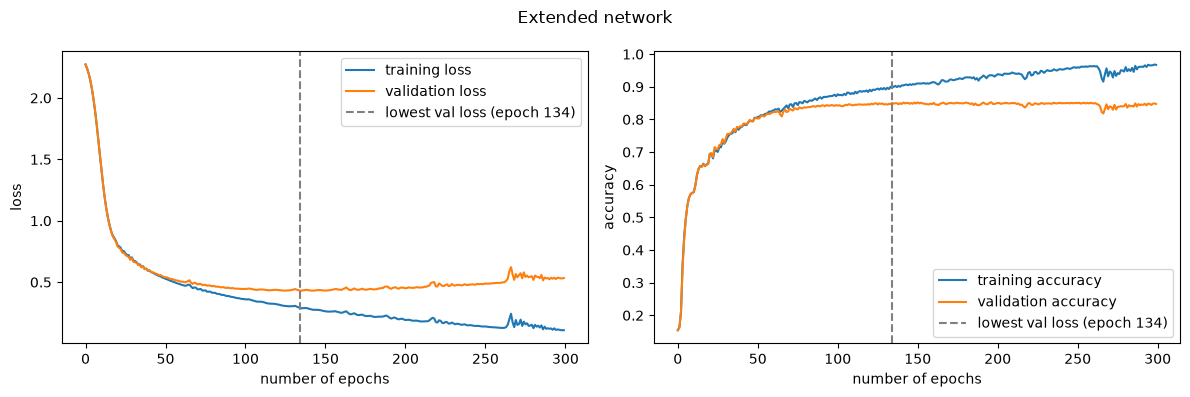

In [106]:
plot_history(history_big, "Extended network")

This is the textbook picture of overfitting:
- The **training loss** keeps decreasing towards zero and the training accuracy approaches 100%: the network starts to memorize the 5,000 training images.
- The **validation loss** reaches its minimum early (dashed line) and then *increases* again, while the validation accuracy stagnates. Compare this with the loss/capacity plots in the lecture.
- The gap between training and validation accuracy is now much larger than in Step 1.

In [107]:
summary(history_small, "last week's network")
summary(history_big, "extended network");

last week's network   : train acc 0.699, val acc 0.695, gap 0.004, val loss 0.891 (lowest: 0.872)
extended network      : train acc 0.960, val acc 0.845, gap 0.115, val loss 0.534 (lowest: 0.431)


**Question:** After the dashed line, the validation *loss* rises again, but the validation *accuracy* stays almost the same. How can both be true at the same time?
(Hint: cross-entropy does not only look at whether a prediction is correct, but also at how confident it is.)

*Your answer:* Die Accuracy zählt nur, ob die Klasse mit der höchsten Wahrscheinlichkeit die richtige ist. Der Cross-Entropy-Loss bewertet dagegen auch, wie sicher das Modell bei seiner Vorhersage ist (−log der Wahrscheinlichkeit der richtigen Klasse). Nach der gestrichelten Linie lernt das Modell die Trainingsdaten auswendig und wird dabei immer überkonfident. Bei den Validierungsbildern, die es falsch klassifiziert, gibt es der falschen Klasse eine immer höhere Wahrscheinlichkeit. Diese Fehler werden vom Loss sehr stark bestraft, weil −log(p) für kleine p stark wächst. Deshalb steigt der Validierungs-Loss. Die Anzahl der richtig klassifizierten Bilder bleibt aber fast gleich, also bleibt auch die Accuracy bei ca. 85 %. Der steigende Validierungs-Loss zeigt somit das Overfitting, obwohl die Accuracy noch stabil aussieht.

## Part 2: Decreasing overfitting

Now it is your turn. Try out the four approaches from the lecture to decrease the overfitting of `BigNetwork`:
1. L2 regularization
2. Dropout
3. Early stopping
4. Capacity reduction

Unless stated otherwise, always start from a **fresh** model (`torch.manual_seed(0)` before creating it), use Adam with `lr=0.0005` and train for 300 epochs, so that the results are comparable with `history_big`.
Each task ends with a check cell that you should run unchanged.

### Task 3: L2 regularization
PyTorch calls L2 regularization *weight decay* and adds it via the optimizer: `torch.optim.Adam(model.parameters(), lr=0.0005, weight_decay=...)`.
1. Train a fresh `BigNetwork` with `weight_decay=0.01`. Store the history in `history_l2` and plot it.
2. Compare the plot with the one of the extended network: what happens to the gap and to the validation loss?

Number of parameters: 798474
Number of training images: 5000
Epoch 0: train loss 2.282, val loss 2.282, train acc 0.161, val acc 0.151
Epoch 30: train loss 0.824, val loss 0.820, train acc 0.653, val acc 0.652
Epoch 60: train loss 0.658, val loss 0.661, train acc 0.766, val acc 0.760
Epoch 90: train loss 0.563, val loss 0.580, train acc 0.807, val acc 0.799
Epoch 120: train loss 0.525, val loss 0.557, train acc 0.814, val acc 0.805
Epoch 150: train loss 0.466, val loss 0.512, train acc 0.849, val acc 0.826
Epoch 180: train loss 0.434, val loss 0.493, train acc 0.863, val acc 0.832
Epoch 210: train loss 0.422, val loss 0.489, train acc 0.857, val acc 0.832
Epoch 240: train loss 0.394, val loss 0.475, train acc 0.871, val acc 0.836
Epoch 270: train loss 0.375, val loss 0.470, train acc 0.881, val acc 0.839


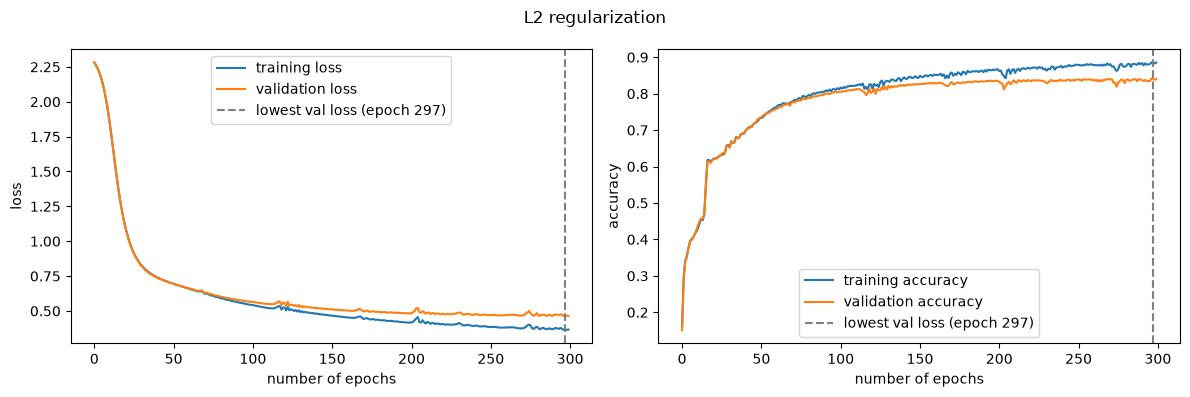

In [108]:
model_l2 = BigNetwork().to(device)
print("Number of parameters:", sum(p.numel() for p in model_l2.parameters()))
print("Number of training images:", len(train_x))

optimizer = torch.optim.Adam(model_l2.parameters(), lr=0.0005, weight_decay=0.01)
history_l2 = train(model_l2, optimizer, no_epochs=300, print_every=30)
plot_history(history_l2, "L2 regularization")

In [109]:
# check for task 3: do not change this cell
_, _, gap_big, val_loss_big = summary(history_big, "no regularization")
_, _, gap_l2, val_loss_l2 = summary(history_l2, "L2 regularization")
assert gap_l2 < 0.6 * gap_big, "the gap should be clearly smaller than without regularization"
assert val_loss_l2 < val_loss_big, "the validation loss at the end should be lower than without regularization"
print("All checks passed!")

no regularization     : train acc 0.960, val acc 0.845, gap 0.115, val loss 0.534 (lowest: 0.431)
L2 regularization     : train acc 0.881, val acc 0.838, gap 0.044, val loss 0.469 (lowest: 0.461)
All checks passed!


### Task 4: Dropout
1. Write a class `DropoutNetwork` that is identical to `BigNetwork`, but applies dropout with `p=0.5` after every ReLU. For this, create a layer `nn.Dropout(p=0.5)` in the constructor and call it in the `forward` method after each `torch.relu`.
2. Train it **without** weight decay. Store the trained model in `model_do`, the history in `history_dropout` and plot it.
3. How does dropout change the validation accuracy? Does it stop the validation loss from rising in our setting?

In [110]:
import torch.nn as nn

class DropoutNetwork(nn.Module): # the class has to inherit from nn.Module
    def __init__(self):
        
        super(DropoutNetwork, self).__init__()  # calling super constructor
        
        # defining layers
        self.hidden1 = nn.Linear(784, 512)
        self.hidden2 = nn.Linear(512, 512)
        self.hidden3 = nn.Linear(512, 256)
        self.output = nn.Linear(256, 10)
        self.dropout = nn.Dropout(p=0.5)

    def forward(self, x):
        
        z1 = self.hidden1(x)
        a1 = self.dropout(torch.relu(z1))
        z2 = self.hidden2(a1)
        a2 = self.dropout(torch.relu(z2))
        z3 = self.hidden3(a2)
        a3 = self.dropout(torch.relu(z3))
        z4 = self.output(a3)
        # note: we do not apply the softmax here!

        return z4

Number of parameters: 798474
Number of training images: 5000
Epoch 0: train loss 2.275, val loss 2.276, train acc 0.148, val acc 0.150
Epoch 30: train loss 0.749, val loss 0.741, train acc 0.696, val acc 0.702
Epoch 60: train loss 0.511, val loss 0.525, train acc 0.808, val acc 0.804
Epoch 90: train loss 0.386, val loss 0.445, train acc 0.861, val acc 0.841
Epoch 120: train loss 0.302, val loss 0.410, train acc 0.893, val acc 0.853
Epoch 150: train loss 0.232, val loss 0.397, train acc 0.921, val acc 0.859
Epoch 180: train loss 0.171, val loss 0.404, train acc 0.942, val acc 0.863
Epoch 210: train loss 0.120, val loss 0.424, train acc 0.962, val acc 0.866
Epoch 240: train loss 0.081, val loss 0.460, train acc 0.978, val acc 0.866
Epoch 270: train loss 0.056, val loss 0.492, train acc 0.987, val acc 0.866


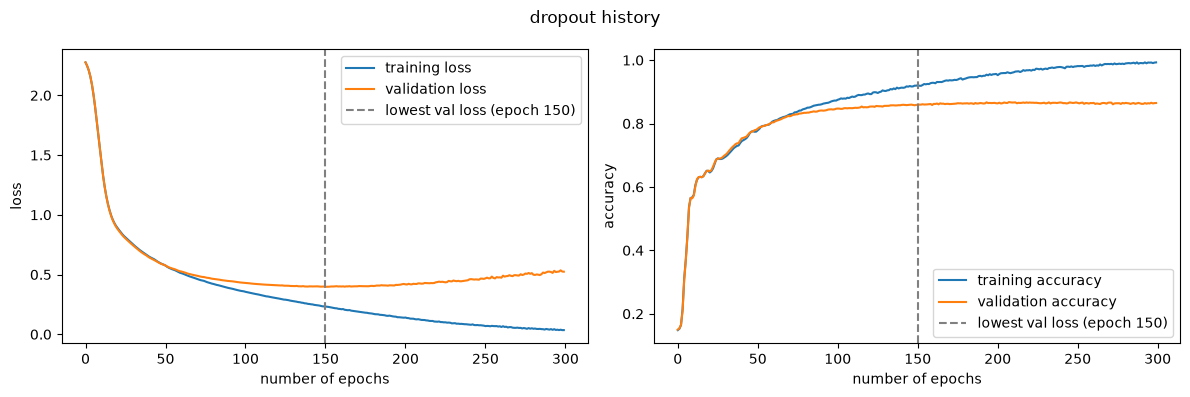

In [111]:
torch.manual_seed(0)
model_do = DropoutNetwork().to(device)
print("Number of parameters:", sum(p.numel() for p in model_do.parameters()))
print("Number of training images:", len(train_x))

optimizer = torch.optim.Adam(model_do.parameters(), lr=0.0005)
history_dropout = train(model_do, optimizer, no_epochs=300, print_every=30)
plot_history(history_dropout, "dropout history")

In [112]:
# check for task 4: do not change this cell
dropout_layers = [m for m in model_do.modules() if isinstance(m, nn.Dropout)]
assert len(dropout_layers) > 0, "DropoutNetwork should contain an nn.Dropout layer"
assert all(m.p == 0.5 for m in dropout_layers), "use dropout with p=0.5"
summary(history_big, "no regularization")
summary(history_dropout, "dropout")
print("All checks passed!")

no regularization     : train acc 0.960, val acc 0.845, gap 0.115, val loss 0.534 (lowest: 0.431)
dropout               : train acc 0.991, val acc 0.864, gap 0.127, val loss 0.515 (lowest: 0.397)
All checks passed!


*Your answer:* Makes validation loss greater. 

### Task 5: Early stopping
1. Copy the `train` function into a new function `train_early_stopping(model, optimizer, max_epochs, patience)`.
2. Whenever the validation loss reaches a new minimum, store a copy of the weights with `best_weights = copy.deepcopy(model.state_dict())` and remember the epoch in `best_epoch`.
   (Use `copy.deepcopy`: without it, the stored `state_dict()` would keep changing together with the model.)
3. Stop the training if the validation loss has not improved for `patience` epochs.
4. After the loop, restore the best weights with `model.load_state_dict(best_weights)`. The function should return `history` and `best_epoch`.
5. Train a fresh `BigNetwork` with `max_epochs=300` and `patience=20`. Store the trained model in `model_es`, the results in `history_es, best_epoch` and plot the history.

In [113]:
import copy

def train_early_stopping(model, optimizer, max_epochs=300, patience=20, print_every=100):
    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
    best, wait = float("inf"), 0
    for epoch in range(max_epochs):

        model.train()   # evaluate() below switches to eval mode, so switch back every epoch (matters for dropout)
        optimizer.zero_grad()
        y_hat = model(train_x)            # all training points (= batch gradient descent)
        loss = loss_func(y_hat, train_y)
        loss.backward()
        optimizer.step()

        train_loss, train_acc = evaluate(model, train_x, train_y)
        val_loss, val_acc = evaluate(model, val_x, val_y)

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_acc"].append(train_acc)
        history["val_acc"].append(val_acc)

        if val_loss < best: 
            best, wait = val_loss, 0 
            best_weights = copy.deepcopy(model.state_dict())
            best_epoch = epoch
        else: 
            wait += 1 
            if wait >= patience: 
                break

        if epoch % print_every == 0:
            print(f"Epoch {epoch}: train loss {train_loss:.3f}, val loss {val_loss:.3f}, "
                  f"train acc {train_acc:.3f}, val acc {val_acc:.3f}")

    model.load_state_dict(best_weights)
    return history, best_epoch

Epoch 0: train loss 2.272, val loss 2.272, train acc 0.154, val acc 0.155
Epoch 30: train loss 0.675, val loss 0.664, train acc 0.733, val acc 0.742
Epoch 60: train loss 0.479, val loss 0.504, train acc 0.828, val acc 0.822
Epoch 90: train loss 0.385, val loss 0.452, train acc 0.864, val acc 0.843
Epoch 120: train loss 0.320, val loss 0.437, train acc 0.891, val acc 0.845
Epoch 150: train loss 0.262, val loss 0.431, train acc 0.910, val acc 0.852


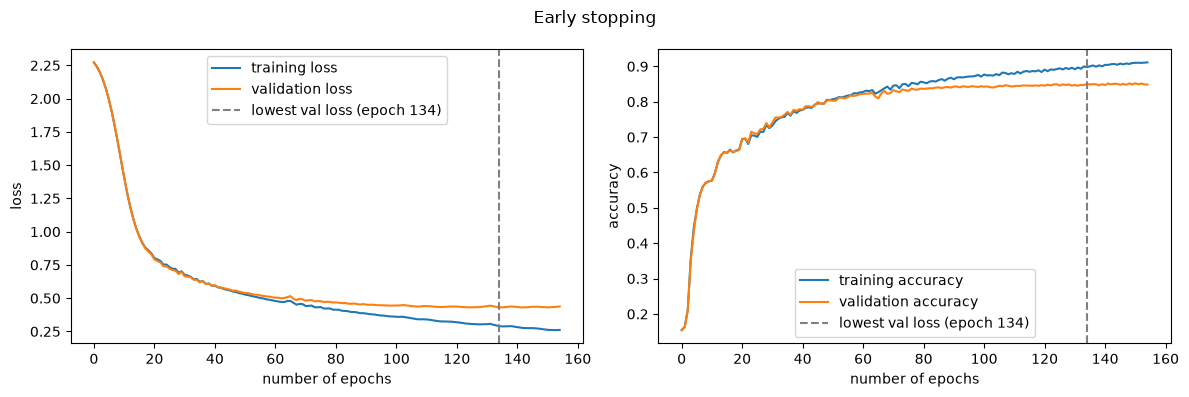

In [114]:
torch.manual_seed(0)
model_es = BigNetwork().to(device)
optimizer = torch.optim.Adam(model_es.parameters(), lr=0.0005)
history_es, best_epoch = train_early_stopping(model_es, optimizer, max_epochs=300, patience=20, print_every=30)
plot_history(history_es, "Early stopping")

In [115]:
# check for task 5: do not change this cell
model_val_loss, _ = evaluate(model_es, val_x, val_y)
assert best_epoch == int(np.argmin(history_es["val_loss"])), "best_epoch is not the epoch with the lowest validation loss"
assert len(history_es["val_loss"]) < 300, "training should have stopped early"
assert abs(model_val_loss - min(history_es["val_loss"])) < 1e-4, "the model does not have the best weights - did you restore them?"
print(f"Stopped after {len(history_es['val_loss'])} epochs, best epoch {best_epoch}. All checks passed!")

Stopped after 155 epochs, best epoch 134. All checks passed!


### Task 6: Capacity reduction
1. Write a class `SmallNetwork` with fewer parameters than `BigNetwork`: one hidden layer of 64 neurons with ReLU activation. (Tip: pass the hidden layer size as a parameter to the constructor, e.g. `def __init__(self, hidden_size=64)`, then it is easy to try other sizes.)
2. Print the number of parameters, train the network and store the history in `history_small_relu`. Plot it.
3. Try one or two other sizes. How small can the network get before it starts to underfit?

Number of parameters: 50890
Epoch 0: train loss 2.268, val loss 2.267, train acc 0.212, val acc 0.207
Epoch 30: train loss 1.194, val loss 1.193, train acc 0.662, val acc 0.670
Epoch 60: train loss 0.837, val loss 0.834, train acc 0.711, val acc 0.715
Epoch 90: train loss 0.699, val loss 0.699, train acc 0.765, val acc 0.769
Epoch 120: train loss 0.613, val loss 0.618, train acc 0.801, val acc 0.800
Epoch 150: train loss 0.551, val loss 0.565, train acc 0.822, val acc 0.816
Epoch 180: train loss 0.505, val loss 0.529, train acc 0.836, val acc 0.827
Epoch 210: train loss 0.469, val loss 0.505, train acc 0.849, val acc 0.833
Epoch 240: train loss 0.440, val loss 0.489, train acc 0.858, val acc 0.835
Epoch 270: train loss 0.415, val loss 0.477, train acc 0.865, val acc 0.838


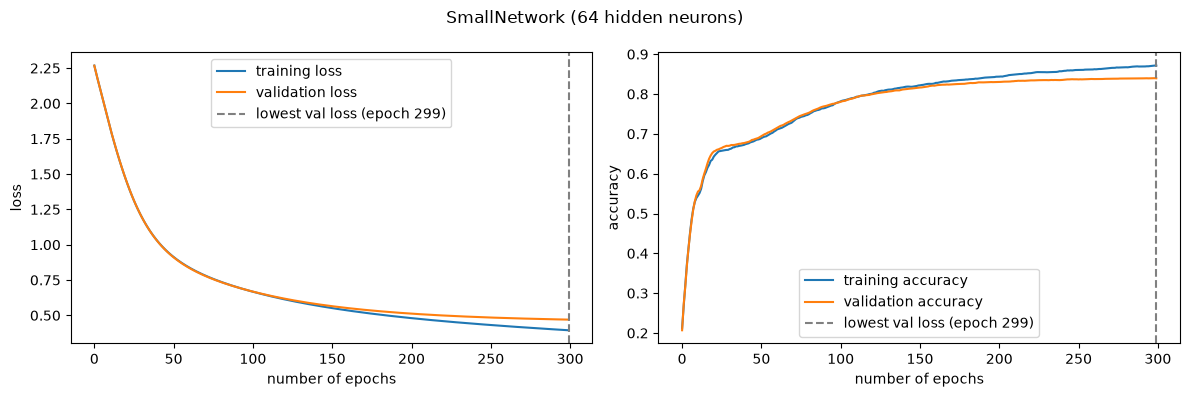

Epoch 0: train loss 2.278, val loss 2.278, train acc 0.117, val acc 0.116
32 neurons (25450 p.) : train acc 0.839, val acc 0.831, gap 0.008, val loss 0.520 (lowest: 0.515)
Epoch 0: train loss 2.289, val loss 2.288, train acc 0.122, val acc 0.121
16 neurons (12730 p.) : train acc 0.810, val acc 0.811, gap -0.001, val loss 0.588 (lowest: 0.581)
Epoch 0: train loss 2.325, val loss 2.326, train acc 0.107, val acc 0.105
4 neurons (3190 p.)   : train acc 0.557, val acc 0.559, gap -0.002, val loss 1.518 (lowest: 1.503)


In [116]:
class SmallNetwork(nn.Module):
    def __init__(self, hidden_size=64):
        
        super(SmallNetwork, self).__init__()  # calling super constructor
        
        # defining layers
        self.hidden = nn.Linear(784, hidden_size)
        self.output = nn.Linear(hidden_size, 10)

    def forward(self, x):
        
        z1 = self.hidden(x)
        a1 = torch.relu(z1)
        z2 = self.output(a1)
        # note: we do not apply the softmax here!

        return z2


torch.manual_seed(0)
model_small = SmallNetwork(hidden_size=64).to(device)
print("Number of parameters:", sum(p.numel() for p in model_small.parameters()))

optimizer = torch.optim.Adam(model_small.parameters(), lr=0.0005)
history_small_relu = train(model_small, optimizer, no_epochs=300, print_every=30)
plot_history(history_small_relu, "SmallNetwork (64 hidden neurons)")

# try other sizes: how small can the network get before it underfits?
histories_sizes = {}
for hidden_size in [32, 16, 4]:
    torch.manual_seed(0)
    model = SmallNetwork(hidden_size).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=0.0005)
    histories_sizes[hidden_size] = train(model, optimizer, no_epochs=300, print_every=1000)
    n_params = sum(p.numel() for p in model.parameters())
    summary(histories_sizes[hidden_size], f"{hidden_size} neurons ({n_params} p.)")


In [117]:
# check for task 6: do not change this cell
_, _, gap_big, val_loss_big = summary(history_big, "BigNetwork")
_, _, gap_cap, val_loss_cap = summary(history_small_relu, "SmallNetwork")
assert gap_cap < 0.6 * gap_big, "the gap should be clearly smaller than with BigNetwork"
assert val_loss_cap < val_loss_big, "the validation loss at the end should be lower than with BigNetwork"
print("All checks passed!")

BigNetwork            : train acc 0.960, val acc 0.845, gap 0.115, val loss 0.534 (lowest: 0.431)
SmallNetwork          : train acc 0.869, val acc 0.839, gap 0.030, val loss 0.472 (lowest: 0.470)
All checks passed!


*Your answer:* Mit 64 Neuronen im Hidden Layer (50.890 Parameter, also ca. 16-mal weniger als `BigNetwork`) schrumpft der Gap von 0,115 auf ca. 0,03, und der Validierungs-Loss steigt nicht mehr an: Bei Epoche 300 sinkt er sogar noch langsam (≈0,47 gegenüber 0,53 bei `BigNetwork`). Die Validierungs-Accuracy (≈0,84) ist fast so gut wie beim großen Netzwerk.

Macht man das Netzwerk noch kleiner, wird der Gap zwar noch kleiner, aber die Accuracy sinkt: Mit 32 Neuronen liegt die Validierungs-Accuracy bei ≈0,83, mit 16 Neuronen bei ≈0,81 (Gap ≈0) und mit 4 Neuronen nur noch bei ≈0,56, wobei Trainings- und Validierungs-Accuracy beide niedrig sind. Ab etwa 16 Neuronen beginnt das Netzwerk zu **underfitten**: Es gibt keinen Gap mehr, aber es kann nicht einmal mehr die Trainingsdaten gut lernen. Mit 4 Neuronen ist es eindeutig underfitted. Etwa 32–64 Neuronen sind ein guter Kompromiss zwischen Overfitting und Underfitting.

### Task 7: Comparison and final test
1. Run the cell below to compare all approaches.
2. Which approach works best for our data? Pick your final model, and only then evaluate it **once** on the test data with `evaluate(model, test_x, test_y)`.
   Why should we not pick the model based on the test accuracy?

In [118]:
for name, h in [("no regularization", history_big), ("L2 regularization", history_l2),
                ("dropout", history_dropout), ("early stopping", history_es),
                ("capacity reduction", history_small_relu)]:
    summary(h, name)

no regularization     : train acc 0.960, val acc 0.845, gap 0.115, val loss 0.534 (lowest: 0.431)
L2 regularization     : train acc 0.881, val acc 0.838, gap 0.044, val loss 0.469 (lowest: 0.461)
dropout               : train acc 0.991, val acc 0.864, gap 0.127, val loss 0.515 (lowest: 0.397)
early stopping        : train acc 0.906, val acc 0.849, gap 0.057, val loss 0.434 (lowest: 0.431)
capacity reduction    : train acc 0.869, val acc 0.839, gap 0.030, val loss 0.472 (lowest: 0.470)


*Your answer:* 

Am besten funktioniert für unsere Daten Early Stopping: Es hat den niedrigsten Validierungs-Loss (0,434), die zweitbeste Validierungs-Accuracy (0,849) und einen kleinen Gap (0,057), außerdem braucht es nur 155 statt 300 Epochen. Die Capacity Reduction hat zwar den kleinsten Gap (0,030), aber eine schlechtere Validierungs-Accuracy (0,839). Ein kleiner Gap allein ist kein gutes Kriterium, da auch ein underfittetes Modell keinen Gap hat. Dropout erreicht zwar die höchste Validierungs-Accuracy (0,864), aber der Validierungs-Loss steigt am Ende wieder an und der Gap ist am größten. Deshalb wählen wir model_es als finales Modell und erhalten auf den Testdaten eine Accuracy von … .

Das Modell darf nicht anhand der Test-Accuracy ausgewählt werden, weil die Testdaten dann indirekt Teil des Trainings- bzw. Auswahlprozesses wären. Wir würden das Modell wählen, das zufällig auf genau diesen Testdaten gut abschneidet, und damit auf die Testdaten „overfitten“. Die Test-Accuracy wäre dann zu optimistisch und keine unabhängige Schätzung mehr dafür, wie gut das Modell auf wirklich neuen Daten funktioniert. Deshalb treffen wir alle Entscheidungen mit den Validierungsdaten und nutzen die Testdaten nur einmal ganz am Ende.